# TP2 OOP and Design Patterns for CSV Data Cleaning

This notebook implements all five exercises from **TP02. OOP.docx** using
`sample_data (2).csv`. Run the cells from top to bottom. The final pipeline
saves a new file, `cleaned_sample_data.csv`, in the same folder as the input.

In [1]:
from abc import ABC, abstractmethod
from functools import wraps
from pathlib import Path
from time import perf_counter

import pandas as pd
from IPython.display import display

# Support running the notebook from either TP2 or its parent TP folder.
CSV_PATH = Path("sample_data (2).csv")
if not CSV_PATH.is_file():
    CSV_PATH = Path("TP2") / "sample_data (2).csv"
if not CSV_PATH.is_file():
    raise FileNotFoundError("Open the notebook from the TP2 or TP folder.")
OUTPUT_PATH = CSV_PATH.with_name("cleaned_sample_data.csv")

### Shared decorators for Exercise 3

Define these helpers first so they can decorate `CSVReader.read()` and
`DataCleaner.clean()` below. `@wraps` preserves the original method's name
and documentation. The `finally` blocks also record completion and timing
if the wrapped method raises an exception; the exception still propagates.

In [2]:
def log_action(func):
    """Log when a function or method starts and finishes."""
    @wraps(func)
    def wrapper(*args, **kwargs):
        print(f"Starting {func.__qualname__}")
        try:
            return func(*args, **kwargs)
        finally:
            print(f"Finished {func.__qualname__}")
    return wrapper


def log_time(func):
    """Print the execution time while preserving the return value."""
    @wraps(func)
    def wrapper(*args, **kwargs):
        start = perf_counter()
        try:
            return func(*args, **kwargs)
        finally:
            elapsed = perf_counter() - start
            print(f"{func.__qualname__} took {elapsed:.6f} seconds")
    return wrapper

## Exercise 1 Build the CSVReader Class

`CSVReader` encapsulates the file path and the loaded data. `read()` loads
the CSV with pandas and returns a copy. `preview(n)` prints the first `n`
rows, loading the file first if necessary.

In [3]:
class CSVReader:
    def __init__(self, file_path):
        self.file_path = Path(file_path)
        self._data = None

    @log_action
    @log_time
    def read(self) -> pd.DataFrame:
        self._data = pd.read_csv(self.file_path)
        return self._data.copy()

    def preview(self, n=5):
        if n < 0:
            raise ValueError("n must be non-negative")
        if self._data is None:
            self.read()
        print(self._data.head(n))

In [4]:
reader = CSVReader(CSV_PATH)
raw_df = reader.read()
print("First three rows:")
reader.preview(3)
print("\nMissing values by column:")
print(raw_df.isna().sum())

Starting CSVReader.read
CSVReader.read took 0.020628 seconds
Finished CSVReader.read
First three rows:
   id     name   age  height_cm  weight_kg         city  score
0   1    Alice  29.0      165.0       68.0     New York   85.0
1   2      Bob   NaN      172.0        NaN  Los Angeles   90.0
2   3  Charlie  35.0      168.0       72.0      Chicago    NaN

Missing values by column:
id           0
name         0
age          3
height_cm    1
weight_kg    1
city         0
score        2
dtype: int64


## Exercise 2 Strategy Pattern for Missing Values

Every strategy implements `handle(df)`. `DataCleaner` delegates the work
to its selected strategy, which can be changed without changing the cleaner.

- `DropMissing` removes rows containing any missing value.
- `FillMean` fills numeric columns with their column means and leaves text unchanged.
- `FillMode` fills each column with its most frequent non-missing value.

A column containing only missing values has neither a mean nor a mode, so
the fill strategies leave that column missing. Each strategy returns a new
DataFrame and preserves the input.

In [5]:
class MissingValueStrategy(ABC):
    @abstractmethod
    def handle(self, df: pd.DataFrame) -> pd.DataFrame:
        pass


class DropMissing(MissingValueStrategy):
    def handle(self, df: pd.DataFrame) -> pd.DataFrame:
        return df.dropna().reset_index(drop=True)


class FillMean(MissingValueStrategy):
    def handle(self, df: pd.DataFrame) -> pd.DataFrame:
        result = df.copy()
        numeric_columns = result.select_dtypes(include="number").columns
        for column in numeric_columns:
            result[column] = result[column].fillna(result[column].mean())
        return result


class FillMode(MissingValueStrategy):
    def handle(self, df: pd.DataFrame) -> pd.DataFrame:
        result = df.copy()
        for column in result.columns:
            modes = result[column].mode(dropna=True)
            if not modes.empty:
                result[column] = result[column].fillna(modes.iloc[0])
        return result

In [6]:
class DataCleaner:
    def __init__(self, strategy: MissingValueStrategy):
        self.strategy = strategy

    def set_strategy(self, strategy: MissingValueStrategy):
        self.strategy = strategy

    @log_action
    @log_time
    def clean(self, df: pd.DataFrame) -> pd.DataFrame:
        return self.strategy.handle(df)

In [7]:
cleaner = DataCleaner(DropMissing())
strategy_results = {}

# Reuse the same cleaner and switch its behavior through strategy objects.
for strategy in (DropMissing(), FillMean(), FillMode()):
    cleaner.set_strategy(strategy)
    result = cleaner.clean(raw_df)
    strategy_results[type(strategy).__name__] = result
    print(f"\n{type(strategy).__name__}: {len(result)} rows, "
          f"{result.isna().sum().sum()} missing values")
    display(result)

Starting DataCleaner.clean
DataCleaner.clean took 0.003151 seconds
Finished DataCleaner.clean

DropMissing: 2 rows, 0 missing values


,id,name,age,height_cm,weight_kg,city,score
0,1,Alice,29.0,165.0,68.0,New York,85.0
1,5,Eva,27.0,160.0,55.0,New York,88.0


Starting DataCleaner.clean
DataCleaner.clean took 0.003065 seconds
Finished DataCleaner.clean

FillMean: 7 rows, 0 missing values


,id,name,age,height_cm,weight_kg,city,score
0,1,Alice,29.00,165.0,68.0,New York,85.0
1,2,Bob,30.25,172.0,70.0,Los Angeles,90.0
2,3,Charlie,35.00,168.0,72.0,Chicago,86.0
3,4,David,30.25,167.0,80.0,Houston,75.0
4,5,Eva,27.00,160.0,55.0,New York,88.0
5,6,Frank,30.00,175.0,85.0,Los Angeles,86.0
6,7,Grace,30.25,162.0,60.0,Chicago,92.0


Starting DataCleaner.clean
DataCleaner.clean took 0.006735 seconds
Finished DataCleaner.clean

FillMode: 7 rows, 0 missing values


,id,name,age,height_cm,weight_kg,city,score
0,1,Alice,29.0,165.0,68.0,New York,85.0
1,2,Bob,27.0,172.0,55.0,Los Angeles,90.0
2,3,Charlie,35.0,168.0,72.0,Chicago,75.0
3,4,David,27.0,160.0,80.0,Houston,75.0
4,5,Eva,27.0,160.0,55.0,New York,88.0
5,6,Frank,30.0,175.0,85.0,Los Angeles,75.0
6,7,Grace,27.0,162.0,60.0,Chicago,92.0


## Exercise 3 Add Decorators for Logging and Timing

`log_action` and `log_time` are defined in the shared setup and applied
directly to methods in `CSVReader` and `DataCleaner` using `@` syntax.
They add behavior around the method without changing its reading or
cleaning logic. Additional wrappers can extend behavior in the same way,
illustrating the Open/Closed Principle.

With `@log_action` above `@log_time`, the start message is printed first,
then the method runs, followed by its elapsed time and finish message.

### How Decorator works. 

```python
def my_decorator(func): 

    def mainfunc(*args): 
        print("Before calling the function")
        response = func(*args)
        print("After calling the function")
        return response

    return mainfunc


@my_decorator
def fetch_data(url:str, path: str): 
    return f"Fetching data from {url} and saving to {path}"


response = fetch_data("https://example.com/data", "/data/file.txt")
print(response)
```

### **Decorator** is a function that wrap another function and we can reuser it again.
```output 
    Before calling the function
    After calling the function
    Fetching data from https://example.com/data and saving to /data/file.txt
```

In [8]:
print("Decorator demonstration:")
logged_df = reader.read()
logged_cleaned_df = DataCleaner(FillMean()).clean(logged_df)
print(f"The decorated methods still return a DataFrame: {logged_cleaned_df.shape}")

Decorator demonstration:
Starting CSVReader.read
CSVReader.read took 0.001348 seconds
Finished CSVReader.read
Starting DataCleaner.clean
DataCleaner.clean took 0.000849 seconds
Finished DataCleaner.clean
The decorated methods still return a DataFrame: (7, 7)


# Exercise 4: Implement Factory Pattern for Data Transformations

##### **Objective:**
+ Practice Factory Pattern for scalable creation of transformation objects.
+ Apply abstraction and composition.
##### **Concept:** Instead of manually creating objects, use a factory that decides what transformation to apply.
##### **Instructions:**
1.  Create an abstract class DataTransform with a method apply(df).
2.  Implement subclasses:
    + NormalizeColumns
    + RemoveDuplicates
    + StandardizeText
3.  Create a TransformFactory that returns transformation objects based on string input.

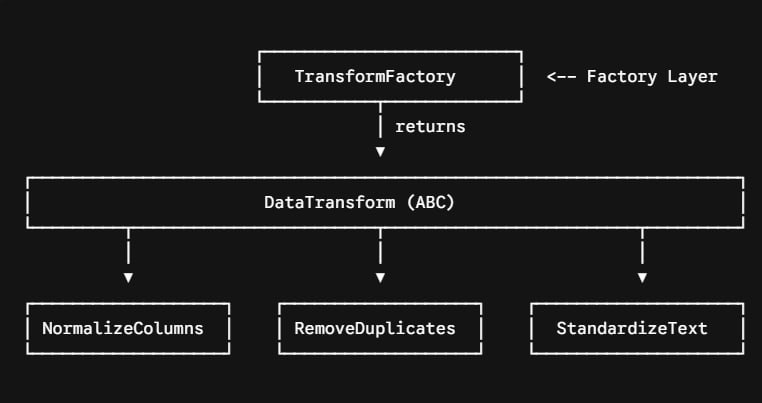

In [9]:
# 1. Abstract Class
class DataTransform(ABC):
    @abstractmethod
    def apply(self, df: pd.DataFrame) -> pd.DataFrame:
        pass

In [10]:
class NormalizeColumns(DataTransform):
    """Make column names lowercase and replace spaces with underscores."""
    def apply(self, df: pd.DataFrame) -> pd.DataFrame:
        result = df.copy()
        result.columns = [str(col).strip().lower().replace(" ", "_")
                          for col in result.columns]
        return result

In [11]:
class RemoveDuplicates(DataTransform):
    """Removes duplicate rows from the DataFrame."""
    def apply(self, df: pd.DataFrame) -> pd.DataFrame:
        return df.drop_duplicates().reset_index(drop=True)

In [12]:
class StandardizeText(DataTransform):
    """Trim text and lowercase it while preserving missing values."""
    def apply(self, df: pd.DataFrame) -> pd.DataFrame:
        result = df.copy()
        text_columns = result.select_dtypes(include=["object", "string"]).columns
        for column in text_columns:
            result[column] = result[column].map(
                lambda value: value.strip().lower() if isinstance(value, str) else value
            )
        return result

In [13]:
# 3. Factory Class
class TransformFactory:
    @staticmethod
    def create_transform(transform_type: str) -> DataTransform:
        transforms = {
            "normalize_columns": NormalizeColumns,
            "remove_duplicates": RemoveDuplicates,
            "standardize_text": StandardizeText,
        }
        key = transform_type.strip().lower()
        if key not in transforms:
            raise ValueError(f"Unknown transformation: '{transform_type}'")
        return transforms[key]()

In [14]:
df = pd.read_csv(CSV_PATH)

# The factory creates each object from its string name.
transformation_names = ["normalize_columns", "standardize_text", "remove_duplicates"]
for name in transformation_names:
    transformer = TransformFactory.create_transform(name)
    df = transformer.apply(df)

print("Data after the factory-created transformations:")
display(df)

Data after the factory-created transformations:


,id,name,age,height_cm,weight_kg,city,score
0,1,alice,29.0,165.0,68.0,new york,85.0
1,2,bob,NaN,172.0,NaN,los angeles,90.0
2,3,charlie,35.0,168.0,72.0,chicago,NaN
3,4,david,NaN,NaN,80.0,houston,75.0
4,5,eva,27.0,160.0,55.0,new york,88.0
5,6,frank,30.0,175.0,85.0,los angeles,NaN
6,7,grace,NaN,162.0,60.0,chicago,92.0


### Abstraction and composition in this example

**Abstraction:** `DataTransform` requires every concrete transformation
to provide `apply(df)`. The caller uses the same interface for all three.

**Composition:** the loop combines separate transformation objects into
one sequence. In Exercise 5, a pipeline object owns and uses these objects.

`@abstractmethod` prevents instantiation until required methods are
implemented. `@staticmethod` lets us call
`TransformFactory.create_transform(...)` without a factory instance.

The supplied CSV already has clean column names and no duplicate rows.
This small example makes the transformations visible, including keeping
a missing text value missing. Standardizing text before removing duplicates
makes the two versions of Alice become one row.

In [15]:
dirty_example = pd.DataFrame({
    " Full Name ": [" Alice ", "alice", " BOB ", None],
    " City ": [" New York ", "new york", " CHICAGO ", None],
})
transformed_example = dirty_example.copy()
for name in transformation_names:
    transformed_example = TransformFactory.create_transform(name).apply(transformed_example)

print("Before:")
display(dirty_example)
print("After:")
display(transformed_example)

Before:


,Full Name,City
0,Alice,New York
1,alice,new york
2,BOB,CHICAGO
3,None,None


After:


,full_name,city
0,alice,new york
1,bob,chicago
2,None,None


## Exercise 5 Full Cleaning Pipeline with the Template Method Pattern

`DataPipeline.run()` defines the fixed workflow:
**load → clean → transform → save**. Its abstract methods are the steps
that subclasses must implement.

`CSVDataPipeline` implements those steps using a `CSVReader`, a
`DataCleaner`, and transformation objects created by `TransformFactory`.
This is composition: the pipeline uses those objects as its components.
Choosing another missing-value strategy or transformation list changes
the configuration while the `run()` workflow stays the same.

In [16]:
class DataPipeline(ABC):
    def run(self) -> pd.DataFrame:
        """Template method: keep the order of processing steps consistent."""
        data = self.load()
        data = self.clean(data)
        data = self.transform(data)
        self.save(data)
        return data

    @abstractmethod
    def load(self) -> pd.DataFrame:
        pass

    @abstractmethod
    def clean(self, df: pd.DataFrame) -> pd.DataFrame:
        pass

    @abstractmethod
    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        pass

    @abstractmethod
    def save(self, df: pd.DataFrame):
        pass

In [17]:
class CSVDataPipeline(DataPipeline):
    def __init__(self, file_path, output_path, strategy, transform_names):
        self.reader = CSVReader(file_path)
        self.cleaner = DataCleaner(strategy)
        self.transforms = [TransformFactory.create_transform(name)
                           for name in transform_names]
        self.output_path = Path(output_path)

    def load(self) -> pd.DataFrame:
        return self.reader.read()

    def clean(self, df: pd.DataFrame) -> pd.DataFrame:
        return self.cleaner.clean(df)

    def transform(self, df: pd.DataFrame) -> pd.DataFrame:
        for transformer in self.transforms:
            df = transformer.apply(df)
        return df

    def save(self, df: pd.DataFrame):
        df.to_csv(self.output_path, index=False)
        print(f"Saved cleaned data to: {self.output_path.resolve()}")

In [18]:
csv_pipeline = CSVDataPipeline(
    file_path=CSV_PATH,
    output_path=OUTPUT_PATH,
    strategy=FillMean(),
    transform_names=["normalize_columns", "standardize_text", "remove_duplicates"],
)

cleaned_df = csv_pipeline.run()
display(cleaned_df)
print("\nMissing values after the complete pipeline:")
print(cleaned_df.isna().sum())

Starting CSVReader.read
CSVReader.read took 0.000950 seconds
Finished CSVReader.read
Starting DataCleaner.clean
DataCleaner.clean took 0.000741 seconds
Finished DataCleaner.clean
Saved cleaned data to: D:\ITC\Year 5\Advance Programming for DS\TP\TP2\cleaned_sample_data.csv


,id,name,age,height_cm,weight_kg,city,score
0,1,alice,29.00,165.0,68.0,new york,85.0
1,2,bob,30.25,172.0,70.0,los angeles,90.0
2,3,charlie,35.00,168.0,72.0,chicago,86.0
3,4,david,30.25,167.0,80.0,houston,75.0
4,5,eva,27.00,160.0,55.0,new york,88.0
5,6,frank,30.00,175.0,85.0,los angeles,86.0
6,7,grace,30.25,162.0,60.0,chicago,92.0



Missing values after the complete pipeline:
id           0
name         0
age          0
height_cm    0
weight_kg    0
city         0
score        0
dtype: int64


### Check the saved result

Confirm that reloading the output reproduces the cleaned data, that all
numeric missing values in this sample were filled, and that the original
data remains unchanged.

In [19]:
saved_df = pd.read_csv(OUTPUT_PATH)
pd.testing.assert_frame_equal(saved_df, cleaned_df, check_dtype=False)
assert cleaned_df.select_dtypes(include="number").notna().all().all()
pd.testing.assert_frame_equal(raw_df, pd.read_csv(CSV_PATH))
print("All pipeline checks passed.")

All pipeline checks passed.
